In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analytics.db import query
from analytics.paths import FIGURES


In [2]:

warmup_result = query("""
    SELECT
        CASE
            WHEN o.order_delivered_customer_date::date
                 > o.order_estimated_delivery_date::date
            THEN 'late'
            ELSE 'on_time'
        END AS delivery_status,

        ROUND(AVG(r.review_score)::numeric, 2) AS avg_review_score,

        COUNT(*) AS review_count

    FROM clean.orders AS o

    JOIN clean.order_reviews AS r
        ON r.order_id = o.order_id

    WHERE o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
      AND o.order_status = 'delivered'

    GROUP BY 1

    ORDER BY delivery_status
""")

warmup_result


,delivery_status,avg_review_score,review_count
0,late,2.27,6409
1,on_time,4.29,89944



### SQL Warm-up — Review Scores and Delivery Performance

We classified reviewed orders into late and on-time deliveries by comparing their actual delivery dates with their estimated delivery dates. We then calculated the average review score and the number of reviews for each group. This analysis helps us understand whether delivery delays are associated with differences in customer satisfaction.


## Part 0 — One sample, one guess

In [3]:

orders = query("""
    SELECT o.order_id, c.customer_state AS state,
           o.order_purchase_timestamp AS purchased,
           o.order_delivered_customer_date AS delivered
    FROM clean.orders AS o
    JOIN clean.customers AS c ON c.customer_id = o.customer_id
    WHERE o.order_delivered_customer_date IS NOT NULL
    ORDER BY o.order_id
""")

orders["days"] = (
    (orders["delivered"] - orders["purchased"])
    .dt.total_seconds() / 86400
)

days = orders["days"]

len(days), round(days.mean(), 2), round(days.std(), 2)



(96476, np.float64(12.56), np.float64(9.55))


### Loading the Delivery Data

We retrieved all delivered orders from PostgreSQL and calculated their delivery duration in days. The dataset contains 96,476 delivered orders, with a mean delivery time of 12.56 days and a standard deviation of 9.55 days. We treat these delivered orders as the population for today's sampling experiments.


In [4]:

rng = np.random.default_rng(13)

five = pd.Series([
    days.sample(30, random_state=rng).mean()
    for _ in range(5)
])

five.round(2).tolist()


[12.92, 9.87, 12.84, 13.02, 11.95]


### Five Random Samples of 30 Orders

We created five random samples, each containing 30 orders, and calculated the mean delivery time of each sample. The results were 12.92, 9.87, 12.84, 13.02 and 11.95 days. Although all samples came from the same population, their averages were different because each sample contained a different selection of orders.


In [5]:
#0.a
rng = np.random.default_rng(13)

five_3000 = pd.Series([
    days.sample(3000, random_state=rng).mean()
    for _ in range(5)
])

pd.DataFrame({
    "sample_mean": five_3000.round(2),
    "difference": (five_3000 - days.mean()).round(2),
    "absolute_difference": (five_3000 - days.mean()).abs().round(2)
})


,sample_mean,difference,absolute_difference
0,12.56,-0.00,0.00
1,12.63,0.07,0.07
2,12.53,-0.03,0.03
3,12.19,-0.37,0.37
4,12.62,0.06,0.06



### Exercise 0.a — Increasing the Sample Size

We repeated the sampling experiment using five samples of 3,000 orders instead of 30. We calculated the mean of each sample and measured its difference from the population mean of 12.56 days. The larger samples generally produce estimates closer to the true mean, showing that increasing the sample size makes the estimate more stable and reduces sampling variability.



### Business Question — Marketing Delivery Claim

A sample of 30 orders with an average of 9.9 days is not enough to support a claim of delivery in under 10 days. Small samples can vary significantly depending on which orders are selected. The population mean is 12.56 days, so the marketing team needs stronger evidence before making this promise.


## Part 1 — Thousands of samples

In [6]:

rng = np.random.default_rng(13)

means_30 = pd.Series([
    days.sample(30, random_state=rng).mean()
    for _ in range(2000)
])

rng = np.random.default_rng(13)

means_300 = pd.Series([
    days.sample(300, random_state=rng).mean()
    for _ in range(2000)
])

round(means_30.mean(), 2), round(means_300.mean(), 2)


(np.float64(12.52), np.float64(12.55))


### Generating Thousands of Sample Averages

We generated 2,000 random samples of 30 orders and another 2,000 samples of 300 orders. We calculated the mean delivery time for each sample. The average of the 30-order sample means was 12.52 days, while the average of the 300-order sample means was 12.55 days. Both values are close to the population mean of 12.56 days.



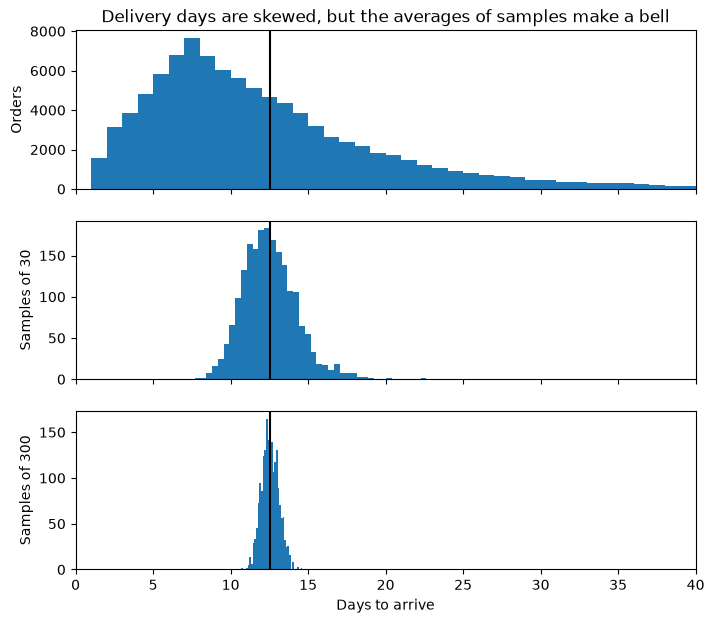

In [7]:

fig, (top, middle, bottom) = plt.subplots(
    3, 1,
    sharex=True,
    figsize=(8, 7)
)

days.plot(kind="hist", bins=range(0, 41), ax=top)

top.set_title("Delivery days are skewed, but the averages of samples make a bell")
top.set_ylabel("Orders")

means_30.plot(kind="hist", bins=40, ax=middle)
middle.set_ylabel("Samples of 30")

means_300.plot(kind="hist", bins=40, ax=bottom)
bottom.set_ylabel("Samples of 300")
bottom.set_xlabel("Days to arrive")

for ax in (top, middle, bottom):
    ax.axvline(days.mean(), color="black")

top.set_xlim(0, 40)

fig.savefig(FIGURES / "day-13-means.png", bbox_inches="tight")

plt.show()



### Visualizing the Central Limit Theorem

We created three histograms to compare the original delivery times with the averages of random samples. The original delivery times are right-skewed, while the averages of 2,000 samples of 30 orders form a more bell-shaped distribution. When the sample size increases to 300, the distribution of averages becomes narrower and more concentrated around the true population mean of 12.56 days. This demonstrates the central limit theorem.


In [8]:
#1.a


prices = query("""
    SELECT price
    FROM clean.order_items
    ORDER BY order_id, order_item_id
    """)["price"]


len(prices), round(prices.mean(), 2), round(prices.std(), 2)


(112650, np.float64(120.65), np.float64(183.63))


### Loading Item Prices

We retrieved the item prices from the clean.order_items table in PostgreSQL. We calculated the number of items, their mean price and their standard deviation. These prices will be used to study how the averages of random samples behave at different sample sizes.


In [9]:
#1.a

rng = np.random.default_rng(13)

price_means_30 = pd.Series([
    prices.sample(30, random_state=rng).mean()
    for _ in range(2000)
])

round(price_means_30.mean(), 2)


np.float64(120.92)


### Sampling Item Prices — Sample Size 30

We generated 2,000 random samples of 30 item prices and calculated the mean price of each sample. We then examined the distribution of these sample averages to see whether they form a bell-shaped pattern.


In [10]:
#1.a

rng = np.random.default_rng(13)

price_means_1000 = pd.Series([
    prices.sample(1000, random_state=rng).mean()
    for _ in range(2000)
])

round(price_means_1000.mean(), 2)


np.float64(120.69)


### Sampling Item Prices — Sample Size 1,000

We repeated the sampling experiment using 2,000 samples of 1,000 item prices each. We calculated the average price of every sample to compare its distribution with the averages from samples of 30 items. Larger samples are expected to produce a narrower distribution of sample averages.



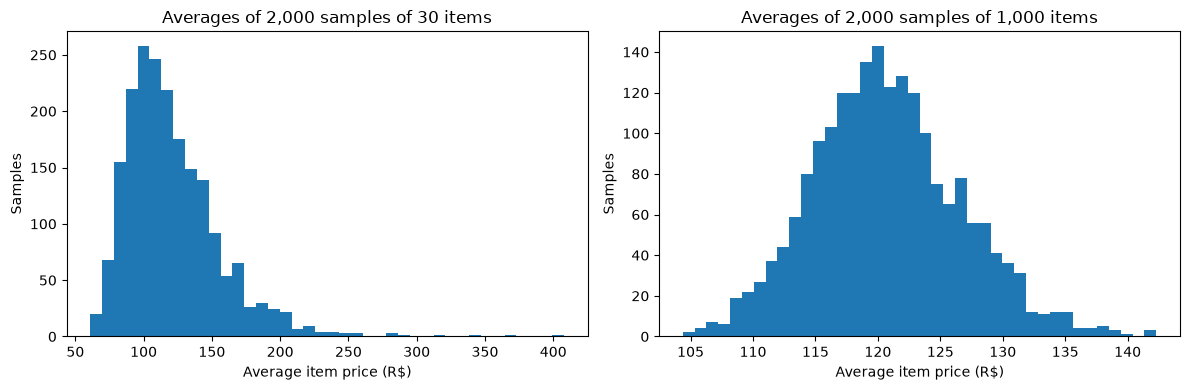

In [11]:
#1.a

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

price_means_30.plot(kind="hist", bins=40, ax=left)
left.set_title("Averages of 2,000 samples of 30 items")
left.set_xlabel("Average item price (R$)")
left.set_ylabel("Samples")

price_means_1000.plot(kind="hist", bins=40, ax=right)
right.set_title("Averages of 2,000 samples of 1,000 items")
right.set_xlabel("Average item price (R$)")
right.set_ylabel("Samples")

plt.tight_layout()
plt.show()



### Exercise 1.a — Central Limit Theorem with Item Prices

We compared the averages of 2,000 samples of 30 item prices with the averages of 2,000 samples of 1,000 item prices. Although the original item prices are right-skewed, the distributions of sample averages become more regular and concentrated around the population mean as the sample size increases. The larger samples produce a narrower distribution.


## Part 2 — How far off is a guess?


In [12]:

sizes = [30, 300, 3000, 30000]

[round(days.std() / np.sqrt(n), 3) for n in sizes]


[np.float64(1.743), np.float64(0.551), np.float64(0.174), np.float64(0.055)]


### Standard Error at Different Sample Sizes

We calculated the standard error for four sample sizes: 30, 300, 3,000 and 30,000 orders. The results were 1.743, 0.551, 0.174 and 0.055 days, respectively. The standard error decreases as the sample size increases, meaning that larger samples provide more stable estimates of the population mean. Increasing the sample size ten times reduces the standard error by approximately the square root of ten.


In [13]:
#2.a

target_se = 0.1

required_n = int(np.ceil((days.std() / target_se) ** 2))

required_n


9114


### Exercise 2.a — Required Sample Size

We rearranged the standard error formula to solve for the required sample size. Using the population standard deviation and a target standard error of 0.1 days, we calculated the minimum whole number of orders needed. We rounded the result up to ensure that the standard error does not exceed the target value.


## Part 3 — A range from one sample: the bootstrap

In [14]:

rng = np.random.default_rng(13)

one_sample = days.sample(300, random_state=rng)

one_sample.mean()


np.float64(12.402953665123457)


### Selecting One Sample of 300 Orders

We selected one random sample containing 300 orders from the full delivery dataset. We calculated its mean delivery time, which is approximately 12.40 days. This sample will be used as the starting point for the bootstrap procedure.


In [15]:

boot_means = pd.Series([
    one_sample.sample(300, replace=True, random_state=rng).mean()
    for _ in range(2000)
])

round(
    one_sample.mean(),
    2
), boot_means.quantile([0.025, 0.975]).round(2).tolist()


(np.float64(12.4), [11.41, 13.41])


### Creating a Bootstrap Confidence Interval

We generated 2,000 bootstrap samples from the original sample of 300 orders, using sampling with replacement. We calculated the mean of each bootstrap sample and used the 2.5th and 97.5th percentiles to create a 95% confidence interval. The original sample mean is 12.40 days, and the interval ranges from 11.41 to 13.41 days. The true population mean of 12.56 days falls inside this interval.


In [16]:
#3.a

boot_medians = pd.Series([
    one_sample.sample(300, replace=True, random_state=rng).median()
    for _ in range(2000)
])

median_range = boot_medians.quantile([0.025, 0.975]).round(2)

median_range


0.025     9.00
0.975    10.77
dtype: float64


### Exercise 3.a — Bootstrap Interval for the Median

We repeated the bootstrap procedure using the median instead of the mean. We generated 2,000 bootstrap samples of 300 observations with replacement and calculated the median of each sample. We then used the 2.5th and 97.5th percentiles to create a 95% bootstrap interval for the median.


## Part 4 — The range by formula

In [17]:

se = one_sample.std() / np.sqrt(300)

se


np.float64(0.5127430894483291)


### Calculating the Standard Error

We calculated the standard error using the standard deviation of the original sample divided by the square root of its size. Since the sample contains 300 orders, we divide the sample standard deviation by the square root of 300. The resulting value is stored in the se variable.


In [18]:

round(one_sample.mean() - 1.96 * se, 2), round(one_sample.mean() + 1.96 * se, 2)



(np.float64(11.4), np.float64(13.41))


### Calculating the Confidence Interval Using a Formula

We calculated the 95% confidence interval using the sample mean plus or minus 1.96 times the standard error. The resulting interval is approximately 11.40 to 13.41 days. This result is very close to the bootstrap interval of 11.41 to 13.41 days, showing that both methods provide similar estimates for this sample.



### Exercise 4.a — Interpreting the Confidence Interval

The 95% confidence interval estimates the population mean delivery time, not the range of delivery times for individual orders. Individual orders may arrive earlier or later than the estimated interval. Therefore, it is incorrect to claim that every order arrives within 11.4 to 13.4 days.


## Part 5 — Small groups, wide ranges

In [19]:

by_state = days.groupby(orders["state"]).agg(["size", "mean", "std"])

by_state["half"] = 1.96 * by_state["std"] / np.sqrt(by_state["size"])

five_states = by_state.loc[["SP", "AL", "AM", "AP", "RR"]]

five_states.round(2)


,size,mean,std,half
state,,,,
SP,40495,8.76,6.75,0.07
AL,397,24.54,11.48,1.13
AM,145,26.43,13.86,2.26
AP,67,27.19,21.38,5.12
RR,41,29.39,27.74,8.49



### Delivery Statistics and Confidence Ranges by State

We grouped delivery times by customer state and calculated the number of orders, mean and standard deviation for each state. We then calculated the half-width of the 95% confidence interval using 1.96 times the standard error. Finally, we selected SP, AL, AM, AP and RR for further comparison. The results show that states with fewer orders generally have wider confidence ranges.


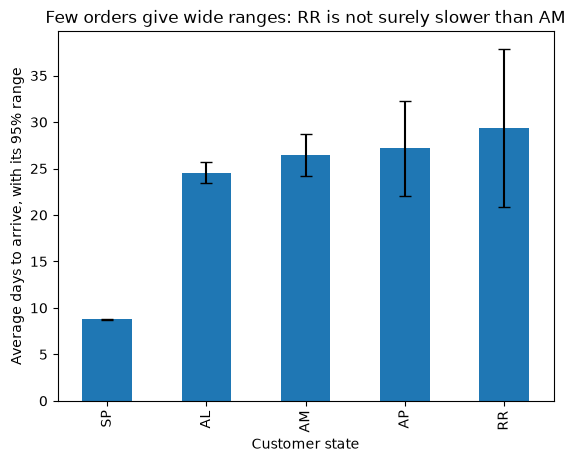

In [20]:

ax = five_states["mean"].plot(
    kind="bar",
    yerr=five_states["half"],
    capsize=4
)

ax.set_title("Few orders give wide ranges: RR is not surely slower than AM")
ax.set_xlabel("Customer state")
ax.set_ylabel("Average days to arrive, with its 95% range")

ax.figure.savefig(FIGURES / "day-13-states.png", bbox_inches="tight")

plt.show()



### State Delivery Averages with Error Bars

We created a bar chart showing the average delivery time for five Brazilian states. We added error bars using the half-width of each state's 95% confidence interval. The chart shows that SP has a very narrow range because it has many orders, while RR has a much wider range because it has only 41 orders.


In [21]:
#5.a

rr = days[orders["state"] == "RR"]

len(rr), round(rr.mean(), 2), round(rr.std(), 2)


(41, np.float64(29.39), np.float64(27.74))


### Selecting Roraima Orders

We filtered the delivery data to keep only orders from Roraima (RR). The resulting sample contains 41 orders, with a mean delivery time of 29.39 days and a standard deviation of 27.74 days. We will use these observations to create a bootstrap confidence interval.


In [22]:
#5.a

rng = np.random.default_rng(13)

rr_boot_means = pd.Series([
    rr.sample(41, replace=True, random_state=rng).mean()
    for _ in range(2000)
])

rr_boot_range = rr_boot_means.quantile([0.025, 0.975]).round(2)

rr_boot_range


0.025    22.31
0.975    38.80
dtype: float64


### Bootstrap Confidence Interval for RR

We generated 2,000 bootstrap samples from the 41 Roraima orders using sampling with replacement. We calculated the mean delivery time for each bootstrap sample and used the 2.5th and 97.5th percentiles to estimate a 95% bootstrap confidence interval for RR's average delivery time.


In [23]:


rr_boot_lower = rr_boot_range.loc[0.025]
rr_boot_upper = rr_boot_range.loc[0.975]

rr_formula_lower = rr.mean() - 1.96 * rr.std() / np.sqrt(len(rr))
rr_formula_upper = rr.mean() + 1.96 * rr.std() / np.sqrt(len(rr))

rr_ranges = pd.DataFrame({
    "method": ["Bootstrap", "Formula"],
    "lower": [rr_boot_lower, rr_formula_lower],
    "upper": [rr_boot_upper, rr_formula_upper]
})

rr_ranges.round(2)


,method,lower,upper
0,Bootstrap,22.31,38.80
1,Formula,20.90,37.88



### Final Comparison of RR Confidence Intervals

We displayed the bootstrap and formula-based confidence intervals in one comparison table. This makes it easier to compare their lower and upper bounds and observe how the two estimation methods differ for the small RR sample.
